## Ans 1

In [1]:
# Requirements: pip install pytesseract opencv-python pillow numpy pandas matplotlib
# Also install the Tesseract OCR engine (Ubuntu: apt install tesseract-ocr, Windows: UB-Mannheim installer)
import os, re, random, difflib
from datetime import date, timedelta
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import pytesseract
from PIL import Image, ImageDraw, ImageFont

# pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"   # needed only on Windows
print("Tesseract version:", pytesseract.get_tesseract_version())
random.seed(7); np.random.seed(7)
plt.rcParams["figure.dpi"] = 80

Tesseract version: 5.3.4


**Step 1 - Dataset.** Medicine-bottle label images are created for four medicines (name, strength, dosage, batch, manufacturing/expiry date, manufacturer) and degraded like a phone photo (tilt, blur, noise, uneven light). You can replace the folder `medicine_labels/` with any downloaded dataset of label images and the rest of the pipeline works unchanged.

In [2]:
today = date.today()
def mmyyyy(d): return f"{d.month:02d}/{d.year}"

# (drug, form, strength, dosage text, batch, mfg offset, expiry offset in days, manufacturer, header colour)
medicines = [
    ("PARACETAMOL TABLETS IP", "tablet",  "500 mg", "1 tablet every 6 hours after food. Maximum 4 tablets in 24 hours.", "PT2405B7", -700, 400, "MediWell Labs Pvt. Ltd.", (200, 230, 255)),
    ("AMOXICILLIN CAPSULES",   "capsule", "250 mg", "1 capsule three times a day for 5 days.",                          "AX1189K2", -900, -90, "CureLife Pharma Ltd.",   (255, 225, 200)),
    ("CETIRIZINE TABLETS",     "tablet",  "10 mg",  "1 tablet once daily at bedtime.",                                  "CZ7730M4", -400, 40,  "HealthFirst Remedies",   (215, 245, 215)),
    ("IBUPROFEN TABLETS",      "tablet",  "400 mg", "1 tablet every 8 hours with water after meals.",                   "IB3021R9", -300, 700, "VitaCare Healthcare",    (255, 240, 190)),
]

def get_font(size, bold=False):
    names = ["DejaVuSans-Bold.ttf", "arialbd.ttf"] if bold else ["DejaVuSans.ttf", "arial.ttf"]
    for n in names:
        try: return ImageFont.truetype(n, size)
        except OSError: pass
    return ImageFont.load_default(size)

def make_label(med):
    name, form, strength, dose, batch, mfg_off, exp_off, maker, color = med
    lines = [
        (name, 38, True),
        (f"Each {form} contains: {name.split()[0].title()} {strength}", 28, False),
        (f"Dosage: {dose}", 26, False),
        (f"Batch No: {batch}", 28, False),
        (f"Mfg: {mmyyyy(today + timedelta(days=mfg_off))}    Exp: {mmyyyy(today + timedelta(days=exp_off))}", 28, True),
        (f"Mfd. by: {maker}", 26, False),
        ("Store below 25 C. Keep out of reach of children.", 24, False),
    ]
    img = Image.new("RGB", (1000, 560), "white")
    d = ImageDraw.Draw(img)
    d.rectangle([0, 0, 1000, 100], fill=color)
    y = 30
    truth = []
    for text, size, bold in lines:
        d.text((40, y), text, font=get_font(size, bold), fill=(20, 20, 20))
        y += 100 if len(truth) == 0 else 62
        truth.append(text)
    return img, truth

def degrade(pil_img, seed):
    rng = np.random.RandomState(seed)
    im = np.array(pil_img)
    h, w = im.shape[:2]
    # lighting gradient
    grad = np.tile(np.linspace(0.75, 1.05, w), (h, 1))[:, :, None]
    im = np.clip(im * grad, 0, 255).astype(np.uint8)
    # tilt
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-4, 4), 1.0)
    im = cv2.warpAffine(im, M, (w, h), borderValue=(235, 235, 235))
    # blur + sensor noise
    im = cv2.GaussianBlur(im, (3, 3), 0)
    im = np.clip(im + rng.normal(0, 8, im.shape), 0, 255).astype(np.uint8)
    return im

os.makedirs("medicine_labels", exist_ok=True)
ground_truth = {}
for i, med in enumerate(medicines):
    label, truth = make_label(med)
    path = f"medicine_labels/label_{i+1}.png"
    cv2.imwrite(path, cv2.cvtColor(degrade(label, seed=i), cv2.COLOR_RGB2BGR))
    ground_truth[path] = truth
print("Images created:", sorted(ground_truth))

Images created: ['medicine_labels/label_1.png', 'medicine_labels/label_2.png', 'medicine_labels/label_3.png', 'medicine_labels/label_4.png']


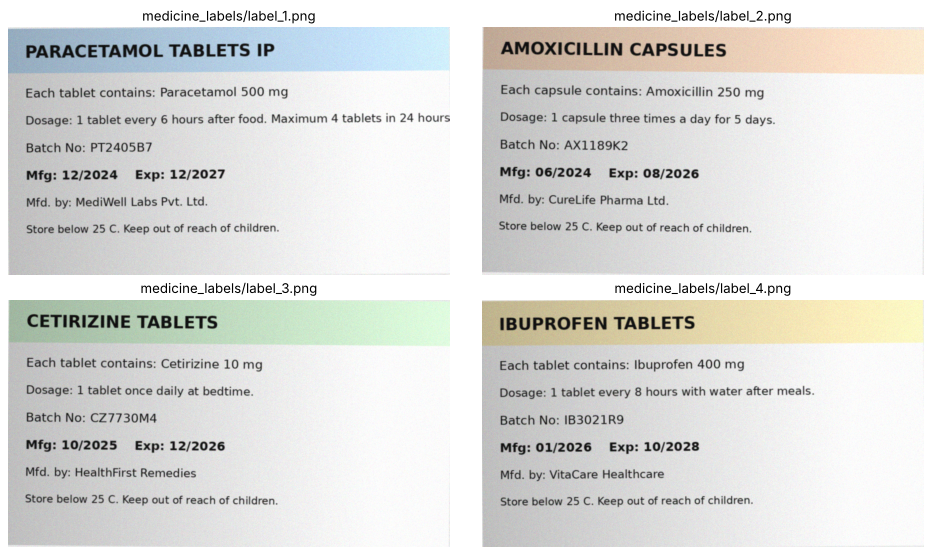

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, p in zip(axes.ravel(), sorted(ground_truth)):
    ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); ax.set_title(p); ax.axis("off")
plt.tight_layout(); plt.show()

**Step 2 - Image pre-processing** (grayscale, upscale, denoise, contrast enhancement, deskew, thresholding) to make the text easier for OCR.

Detected skew angle corrected: -0.40 degrees


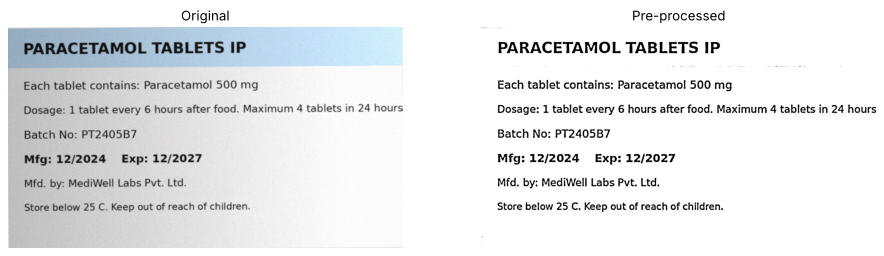

In [4]:
def deskew(gray):
    inv = cv2.bitwise_not(gray)
    thr = cv2.threshold(inv, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]
    coords = np.column_stack(np.where(thr > 0))
    angle = cv2.minAreaRect(coords)[-1]
    angle = -(90 + angle) if angle < -45 else -angle
    if angle > 45: angle -= 90
    h, w = gray.shape
    M = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    return cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE), angle

def preprocess(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    gray = cv2.fastNlMeansDenoising(gray, None, h=12)
    gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    gray, angle = deskew(gray)
    binary = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 41, 15)
    return binary, angle

sample = cv2.imread("medicine_labels/label_1.png")
processed, angle = preprocess(sample)
print("Detected skew angle corrected: %.2f degrees" % angle)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(cv2.cvtColor(sample, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original"); ax[0].axis("off")
ax[1].imshow(processed, cmap="gray"); ax[1].set_title("Pre-processed"); ax[1].axis("off")
plt.show()

**Step 3 - Text extraction with OCR** (Tesseract) and a check of how much pre-processing helps, measured as character similarity with the true label text.

In [5]:
def run_ocr(img):
    return pytesseract.image_to_string(img, config="--oem 3 --psm 6")

def similarity(a, b):
    norm = lambda s: re.sub(r"\s+", " ", s).strip().upper()
    return difflib.SequenceMatcher(None, norm(a), norm(b)).ratio()

rows = []
for path in sorted(ground_truth):
    img = cv2.imread(path)
    truth = " ".join(ground_truth[path])
    raw_text = run_ocr(img)
    pre_text = run_ocr(preprocess(img)[0])
    rows.append([path, round(similarity(raw_text, truth) * 100, 1), round(similarity(pre_text, truth) * 100, 1)])
acc = pd.DataFrame(rows, columns=["Image", "OCR accuracy raw (%)", "OCR accuracy pre-processed (%)"])
print(acc.to_string(index=False))
print("\nAverage:", acc.iloc[:, 1:].mean().round(1).to_dict())
print("\n--- OCR text of label_1 (pre-processed) ---")
print(run_ocr(preprocess(sample)[0]))

                      Image  OCR accuracy raw (%)  OCR accuracy pre-processed (%)
medicine_labels/label_1.png                  94.3                            99.8
medicine_labels/label_2.png                  95.3                            90.1
medicine_labels/label_3.png                  99.5                            99.5
medicine_labels/label_4.png                  94.5                            99.6

Average: {'OCR accuracy raw (%)': 95.9, 'OCR accuracy pre-processed (%)': 97.2}

--- OCR text of label_1 (pre-processed) ---


PARACETAMOL TABLETS IP

Each tablet contains: Paracetamol 500 mg

Dosage: 1 tablet every 6 hours after food. Maximum 4 tablets in 24 hours
Batch No: PT2405B7

Mfg: 12/2024 Exp: 12/2027

Mfd. by: MediWell Labs Pvt. Ltd.

Store below 25 C. Keep out of reach of children.



**Step 4 - Understanding the text** (information extraction with regular expressions and fuzzy matching against a drug knowledge base).

In [6]:
drug_db = {
    "PARACETAMOL": {"use": "pain relief and fever", "max_daily": "4000 mg (8 tablets of 500 mg)", "warning": "Avoid alcohol; do not combine with other paracetamol products."},
    "AMOXICILLIN": {"use": "bacterial infections (antibiotic)", "max_daily": "as prescribed by the doctor", "warning": "Complete the full course; check for penicillin allergy."},
    "CETIRIZINE":  {"use": "allergies, sneezing and itching", "max_daily": "10 mg once a day", "warning": "May cause drowsiness; avoid driving."},
    "IBUPROFEN":   {"use": "pain, inflammation and fever", "max_daily": "1200 mg without a doctor's advice", "warning": "Take after food; avoid in stomach ulcers."},
}

def to_month_end(m, y):
    m, y = int(m), int(y)
    nxt = date(y + (m == 12), (m % 12) + 1, 1)
    return nxt - timedelta(days=1)

def extract_info(text):
    t = text.replace("|", "I")
    info = {}
    # medicine name: fuzzy match every word against the drug database
    best, score = None, 0
    for w in re.findall(r"[A-Za-z]{5,}", t):
        m = difflib.get_close_matches(w.upper(), drug_db.keys(), n=1, cutoff=0.7)
        if m:
            s = difflib.SequenceMatcher(None, w.upper(), m[0]).ratio()
            if s > score: best, score = m[0], s
    info["medicine"] = best
    s = re.search(r"(\d+(?:\.\d+)?)\s?(mg|mcg|ml|g)\b", t, re.I);                 info["strength"] = s.group(0) if s else None
    d = re.search(r"Dosage\s*[:\-]?\s*(.+)", t, re.I);                            info["dosage"] = d.group(1).strip() if d else None
    b = re.search(r"Batch\s*(?:No\.?)?\s*[:\-]?\s*([A-Z0-9]{5,})", t, re.I);     info["batch"] = b.group(1).upper() if b else None
    mf = re.search(r"M\w{1,2}g\.?\s*[:\-]?\s*(\d{1,2})\s*/\s*(20\d{2})", t, re.I); info["mfg"] = f"{mf.group(1)}/{mf.group(2)}" if mf else None
    e = re.search(r"E\w{1,2}p\.?\s*[:\-]?\s*(\d{1,2})\s*/\s*(20\d{2})", t, re.I)
    info["expiry"] = f"{e.group(1)}/{e.group(2)}" if e else None
    info["expiry_date"] = to_month_end(e.group(1), e.group(2)) if e else None
    c = re.search(r"(?:Mfd|Manufactured)\.?\s*by\s*[:\-]?\s*(.+)", t, re.I);   info["manufacturer"] = c.group(1).strip() if c else None
    return info

for path in sorted(ground_truth):
    print(path, extract_info(run_ocr(preprocess(cv2.imread(path))[0])))

medicine_labels/label_1.png {'medicine': 'PARACETAMOL', 'strength': '500 mg', 'dosage': '1 tablet every 6 hours after food. Maximum 4 tablets in 24 hours', 'batch': 'PT2405B7', 'mfg': '12/2024', 'expiry': '12/2027', 'expiry_date': datetime.date(2027, 12, 31), 'manufacturer': 'MediWell Labs Pvt. Ltd.'}


medicine_labels/label_2.png {'medicine': 'AMOXICILLIN', 'strength': '250 mg', 'dosage': '1 capsule three times a day for 5 days.', 'batch': 'AX1189K2', 'mfg': '06/2024', 'expiry': '08/2026', 'expiry_date': datetime.date(2026, 8, 31), 'manufacturer': 'CureLife Pharma Ltd.'}


medicine_labels/label_3.png {'medicine': 'CETIRIZINE', 'strength': '10 mg', 'dosage': '1 tablet once daily at bedtime.', 'batch': 'CZ7730M4', 'mfg': '10/2025', 'expiry': '12/2026', 'expiry_date': datetime.date(2026, 12, 31), 'manufacturer': 'HealthFirst Remedies'}


medicine_labels/label_4.png {'medicine': 'IBUPROFEN', 'strength': '400 mg', 'dosage': '1 tablet every 8 hours with water after meals.', 'batch': 'IB3021R9', 'mfg': '01/2026', 'expiry': '10/2028', 'expiry_date': datetime.date(2028, 10, 31), 'manufacturer': 'VitaCare Healthcare'}


**Step 5 - Cognitive assistant** that reads the bottle, understands it, checks expiry and gives safety advice in plain language (the final message can be given to any text-to-speech engine for visually impaired users).

In [7]:
class MedicineLabelAssistant:
    def __init__(self, warn_days=60):
        self.warn_days = warn_days

    def read(self, path):
        img = cv2.imread(path)
        text = run_ocr(preprocess(img)[0])
        return text, extract_info(text)

    def advise(self, info):
        notes, status = [], "SAFE"
        if info["expiry_date"]:
            left = (info["expiry_date"] - date.today()).days
            if left < 0:
                status = "EXPIRED"; notes.append(f"This medicine expired {abs(left)} days ago. Do NOT use it and dispose of it safely.")
            elif left <= self.warn_days:
                status = "EXPIRING SOON"; notes.append(f"It expires in {left} days. Use it quickly or replace it.")
            else:
                notes.append(f"It is valid for another {left} days.")
        else:
            status = "UNKNOWN"; notes.append("The expiry date could not be read. Please check the bottle manually.")
        k = drug_db.get(info["medicine"])
        if k:
            notes.append(f"{info['medicine'].title()} {info['strength'] or ''} is used for {k['use']}.")
            notes.append(f"Directions on the label: {info['dosage']}" if info["dosage"] else "Dosage could not be read.")
            notes.append(f"Maximum daily dose: {k['max_daily']}. Caution: {k['warning']}")
        notes.append("This is an automated reading and not medical advice - consult a doctor or pharmacist when in doubt.")
        return status, notes

    def run(self, path):
        text, info = self.read(path)
        status, notes = self.advise(info)
        print("=" * 80)
        print(f"Image : {path}")
        print(f"Medicine: {info['medicine']} | Strength: {info['strength']} | Batch: {info['batch']}")
        print(f"Mfg: {info['mfg']} | Expiry: {info['expiry']} | Manufacturer: {info['manufacturer']}")
        print(f"STATUS: {status}")
        for n in notes: print("  -", n)
        return status, info

assistant = MedicineLabelAssistant()
summary = []
for path in sorted(ground_truth):
    status, info = assistant.run(path)
    summary.append([path, info["medicine"], info["strength"], info["expiry"], status])

Image : medicine_labels/label_1.png
Medicine: PARACETAMOL | Strength: 500 mg | Batch: PT2405B7
Mfg: 12/2024 | Expiry: 12/2027 | Manufacturer: MediWell Labs Pvt. Ltd.
STATUS: SAFE
  - It is valid for another 407 days.
  - Paracetamol 500 mg is used for pain relief and fever.
  - Directions on the label: 1 tablet every 6 hours after food. Maximum 4 tablets in 24 hours
  - Maximum daily dose: 4000 mg (8 tablets of 500 mg). Caution: Avoid alcohol; do not combine with other paracetamol products.
  - This is an automated reading and not medical advice - consult a doctor or pharmacist when in doubt.


Image : medicine_labels/label_2.png
Medicine: AMOXICILLIN | Strength: 250 mg | Batch: AX1189K2
Mfg: 06/2024 | Expiry: 08/2026 | Manufacturer: CureLife Pharma Ltd.
STATUS: EXPIRED
  - This medicine expired 80 days ago. Do NOT use it and dispose of it safely.
  - Amoxicillin 250 mg is used for bacterial infections (antibiotic).
  - Directions on the label: 1 capsule three times a day for 5 days.
  - Maximum daily dose: as prescribed by the doctor. Caution: Complete the full course; check for penicillin allergy.
  - This is an automated reading and not medical advice - consult a doctor or pharmacist when in doubt.


Image : medicine_labels/label_3.png
Medicine: CETIRIZINE | Strength: 10 mg | Batch: CZ7730M4
Mfg: 10/2025 | Expiry: 12/2026 | Manufacturer: HealthFirst Remedies
STATUS: EXPIRING SOON
  - It expires in 42 days. Use it quickly or replace it.
  - Cetirizine 10 mg is used for allergies, sneezing and itching.
  - Directions on the label: 1 tablet once daily at bedtime.
  - Maximum daily dose: 10 mg once a day. Caution: May cause drowsiness; avoid driving.
  - This is an automated reading and not medical advice - consult a doctor or pharmacist when in doubt.


Image : medicine_labels/label_4.png
Medicine: IBUPROFEN | Strength: 400 mg | Batch: IB3021R9
Mfg: 01/2026 | Expiry: 10/2028 | Manufacturer: VitaCare Healthcare
STATUS: SAFE
  - It is valid for another 712 days.
  - Ibuprofen 400 mg is used for pain, inflammation and fever.
  - Directions on the label: 1 tablet every 8 hours with water after meals.
  - Maximum daily dose: 1200 mg without a doctor's advice. Caution: Take after food; avoid in stomach ulcers.
  - This is an automated reading and not medical advice - consult a doctor or pharmacist when in doubt.


In [8]:
pd.DataFrame(summary, columns=["Image", "Medicine", "Strength", "Expiry", "Status"])

,Image,Medicine,Strength,Expiry,Status
0,medicine_labels/label_1.png,PARACETAMOL,500 mg,12/2027,SAFE
1,medicine_labels/label_2.png,AMOXICILLIN,250 mg,08/2026,EXPIRED
2,medicine_labels/label_3.png,CETIRIZINE,10 mg,12/2026,EXPIRING SOON
3,medicine_labels/label_4.png,IBUPROFEN,400 mg,10/2028,SAFE


## Ans 2

In [9]:
# Requirements: pip install deepface tf-keras opencv-python matplotlib pandas
import os, re, glob, shutil, subprocess, warnings
from collections import Counter
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from deepface import DeepFace
plt.rcParams["figure.dpi"] = 80

def load_small(path, max_w=400):
    img = cv2.imread(path); s = max_w / img.shape[1]
    return cv2.resize(img, None, fx=s, fy=s), s

**Step 1 - Dataset.** A few face photographs with different expressions are taken from the public test-image folder of the DeepFace GitHub repository (the emotion model itself is pre-trained on the FER-2013 dataset).

8 images: ['faces/face_1.jpg', 'faces/face_3.jpg', 'faces/face_16.jpg', 'faces/face_18.jpg', 'faces/face_19.jpg', 'faces/face_23.jpg', 'faces/face_31.jpg', 'faces/face_32.jpg']


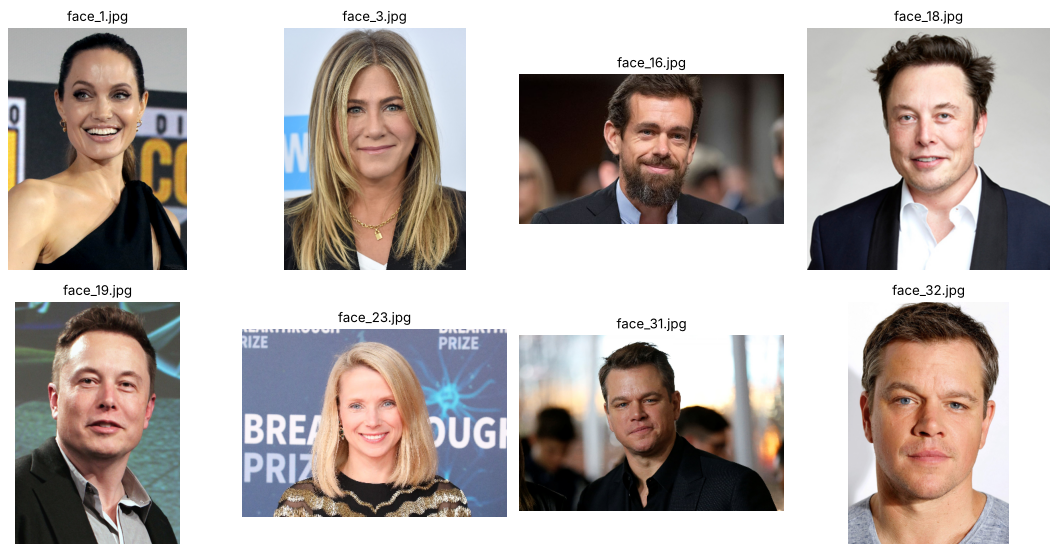

In [10]:
if not os.path.exists("dfrepo"):
    subprocess.run(["git", "clone", "--depth", "1", "-q", "https://github.com/serengil/deepface.git", "dfrepo"], check=True)

os.makedirs("faces", exist_ok=True)
for i in [1, 3, 16, 19, 31, 32, 18, 23]:
    shutil.copy(f"dfrepo/tests/unit/dataset/img{i}.jpg", f"faces/face_{i}.jpg")
face_files = sorted(glob.glob("faces/*.jpg"), key=lambda f: int(re.findall(r"(\d+)", f)[0]))
print(len(face_files), "images:", face_files)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, f in zip(axes.ravel(), face_files):
    ax.imshow(cv2.cvtColor(load_small(f)[0], cv2.COLOR_BGR2RGB)); ax.set_title(os.path.basename(f)); ax.axis("off")
plt.tight_layout(); plt.show()

**Step 2 - Face detection** with OpenCV's Haar cascade (the same detector is used inside the emotion pipeline). When several boxes appear (false detections on background), the largest box is taken as the main face.

In [11]:
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

def detect_faces(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))

for f in face_files:
    faces = detect_faces(cv2.imread(f))
    largest = max(faces, key=lambda b: b[2] * b[3]) if len(faces) else None
    print(f"{os.path.basename(f):13s} faces found: {len(faces)}   largest face (x, y, w, h): {None if largest is None else tuple(int(v) for v in largest)}")

face_1.jpg    faces found: 1   largest face (x, y, w, h): (345, 211, 769, 769)


face_3.jpg    faces found: 3   largest face (x, y, w, h): (363, 349, 835, 835)
face_16.jpg   faces found: 1   largest face (x, y, w, h): (273, 72, 248, 248)


face_18.jpg   faces found: 1   largest face (x, y, w, h): (333, 230, 526, 526)


face_19.jpg   faces found: 1   largest face (x, y, w, h): (227, 218, 684, 684)


face_23.jpg   faces found: 1   largest face (x, y, w, h): (811, 419, 721, 721)


face_31.jpg   faces found: 1   largest face (x, y, w, h): (768, 359, 695, 695)


face_32.jpg   faces found: 1   largest face (x, y, w, h): (99, 302, 817, 817)


**Step 3 - Facial expression recognition.** A CNN trained on FER-2013 predicts the probability of 7 emotions: angry, disgust, fear, happy, sad, surprise and neutral.

In [12]:
EMOTIONS = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]

def detect_emotion(path):
    res = DeepFace.analyze(path, actions=["emotion"], detector_backend="opencv", enforce_detection=True, silent=True)[0]
    scores = {e: float(res["emotion"][e]) for e in EMOTIONS}
    r = res["region"]
    return {"dominant": res["dominant_emotion"], "confidence": scores[res["dominant_emotion"]],
            "scores": scores, "box": (r["x"], r["y"], r["w"], r["h"])}

results = {f: detect_emotion(f) for f in face_files}
table = pd.DataFrame([{"Image": os.path.basename(f), "Emotion": r["dominant"], "Confidence %": round(r["confidence"], 1)} for f, r in results.items()])
table

,Image,Emotion,Confidence %
0,face_1.jpg,happy,100.0
1,face_3.jpg,happy,95.5
2,face_16.jpg,sad,69.3
3,face_18.jpg,neutral,99.0
4,face_19.jpg,sad,61.8
5,face_23.jpg,happy,100.0
6,face_31.jpg,angry,98.5
7,face_32.jpg,neutral,99.3


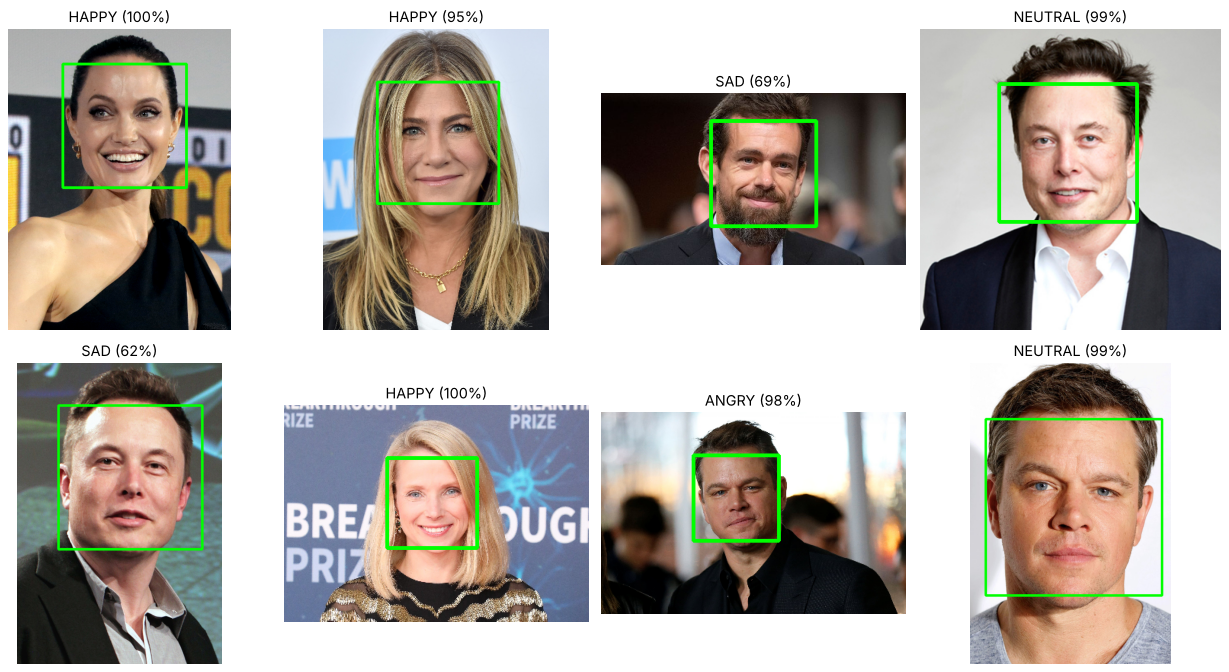

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, (f, r) in zip(axes.ravel(), results.items()):
    img, sc = load_small(f); x, y, w, h = [int(v * sc) for v in r["box"]]
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 3)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{r['dominant'].upper()} ({r['confidence']:.0f}%)", fontsize=13)
plt.tight_layout(); plt.show()

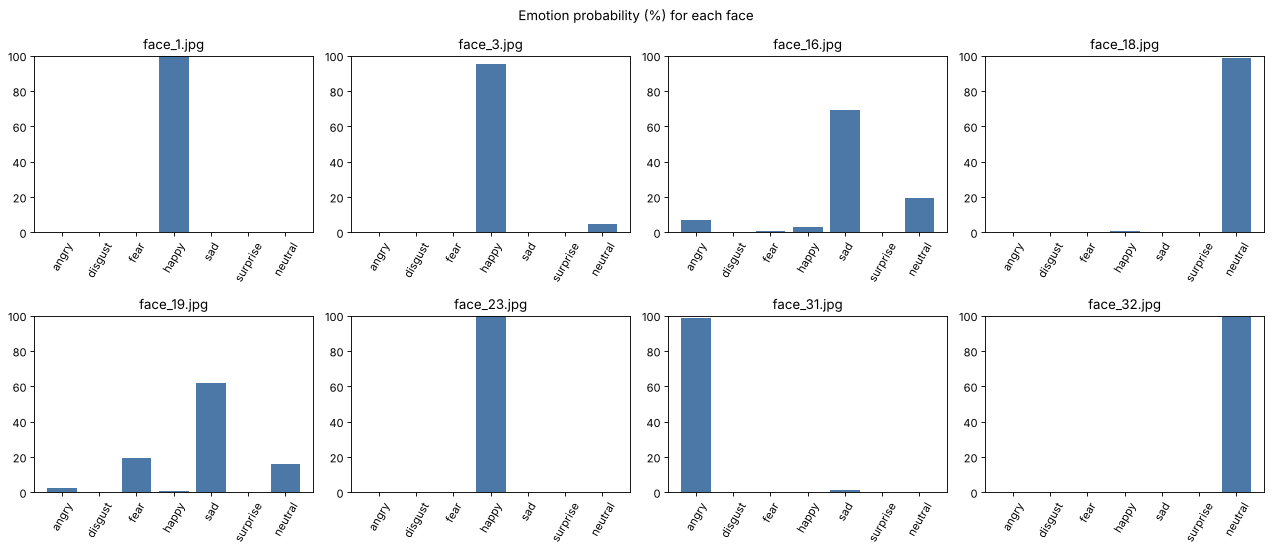

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (f, r) in zip(axes.ravel(), results.items()):
    ax.bar(EMOTIONS, [r["scores"][e] for e in EMOTIONS], color="#4c78a8")
    ax.set_title(os.path.basename(f)); ax.set_ylim(0, 100); ax.tick_params(axis="x", rotation=60)
plt.suptitle("Emotion probability (%) for each face"); plt.tight_layout(); plt.show()

**Step 4 - Emotion-aware cognitive assistant.** The assistant maps the detected emotion to a mood category, adapts its tone, and suggests a helpful action. If the model is not confident, the assistant asks the user instead of assuming.

In [15]:
RESPONSES = {
    "happy":    ("Positive", "You look happy today! That is great to see.", "Keep the momentum - this is a good time to tackle a creative or challenging task."),
    "surprise": ("Neutral",  "You look surprised. Did something unexpected happen?", "Take a moment to process it. I can help you look up details if needed."),
    "neutral":  ("Neutral",  "You seem calm and focused.", "Shall I continue with your tasks, or would you like a quick summary of your day?"),
    "sad":      ("Negative", "You seem a bit down. I am here if you want to talk.", "Maybe a short break, some music, or a chat with a friend could help."),
    "angry":    ("Negative", "You look frustrated. I understand things can be stressful.", "Try a few slow deep breaths. I can pause notifications for 15 minutes."),
    "fear":     ("Negative", "You look worried or anxious.", "Let us break the problem into small steps. I can help you plan them one by one."),
    "disgust":  ("Negative", "Something seems to be bothering you.", "Would you like me to change the topic or remove what is causing discomfort?"),
}

def assistant_reply(emotion, confidence, threshold=50):
    if confidence < threshold:
        return "Uncertain", "I am not sure how you are feeling right now.", "Could you tell me how you feel today?"
    return RESPONSES[emotion]

for f, r in results.items():
    mood, msg, action = assistant_reply(r["dominant"], r["confidence"])
    print(f"[{os.path.basename(f)}] detected: {r['dominant']} ({r['confidence']:.0f}%) -> mood: {mood}")
    print(f"   Assistant : {msg}")
    print(f"   Suggestion: {action}\n")

[face_1.jpg] detected: happy (100%) -> mood: Positive
   Assistant : You look happy today! That is great to see.
   Suggestion: Keep the momentum - this is a good time to tackle a creative or challenging task.

[face_3.jpg] detected: happy (95%) -> mood: Positive
   Assistant : You look happy today! That is great to see.
   Suggestion: Keep the momentum - this is a good time to tackle a creative or challenging task.

[face_16.jpg] detected: sad (69%) -> mood: Negative
   Assistant : You seem a bit down. I am here if you want to talk.
   Suggestion: Maybe a short break, some music, or a chat with a friend could help.

[face_18.jpg] detected: neutral (99%) -> mood: Neutral
   Assistant : You seem calm and focused.
   Suggestion: Shall I continue with your tasks, or would you like a quick summary of your day?

[face_19.jpg] detected: sad (62%) -> mood: Negative
   Assistant : You seem a bit down. I am here if you want to talk.
   Suggestion: Maybe a short break, some music, or a chat with

**Step 5 - Mood tracking over a session.** Treating the images as consecutive webcam frames, the assistant keeps a running record of emotions and gives an overall summary and proactive support.

Emotion timeline : ['happy', 'happy', 'sad', 'neutral', 'sad', 'happy', 'angry', 'neutral']
Emotion counts   : {'happy': 3, 'sad': 2, 'neutral': 2, 'angry': 1}
Mood counts      : {'Positive': 3, 'Negative': 3, 'Neutral': 2}


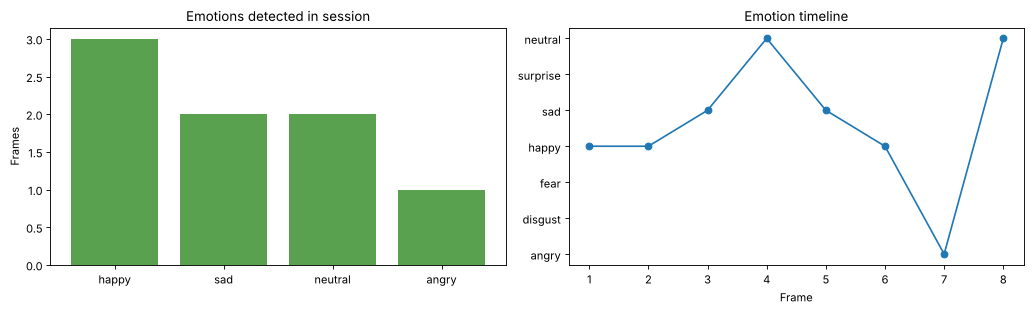


Session summary: most frequent emotion = happy; negative moods = 38% of frames.
Assistant: Overall you seem to be doing well. Keep it up!


In [16]:
timeline = [r["dominant"] for r in results.values()]
counts = Counter(timeline)
mood_of = {e: RESPONSES[e][0] for e in EMOTIONS}
mood_counts = Counter(mood_of[e] for e in timeline)
print("Emotion timeline :", timeline)
print("Emotion counts   :", dict(counts))
print("Mood counts      :", dict(mood_counts))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(counts.keys(), counts.values(), color="#59a14f"); ax[0].set_title("Emotions detected in session"); ax[0].set_ylabel("Frames")
ax[1].plot(range(1, len(timeline) + 1), [EMOTIONS.index(e) for e in timeline], marker="o")
ax[1].set_yticks(range(len(EMOTIONS))); ax[1].set_yticklabels(EMOTIONS); ax[1].set_xlabel("Frame"); ax[1].set_title("Emotion timeline")
plt.tight_layout(); plt.show()

neg_ratio = mood_counts.get("Negative", 0) / len(timeline)
dominant = counts.most_common(1)[0][0]
print(f"\nSession summary: most frequent emotion = {dominant}; negative moods = {neg_ratio*100:.0f}% of frames.")
if neg_ratio >= 0.4:
    print("Assistant: You seem to have had a stressful session. Let us take a short break - would you like a relaxing playlist or a breathing exercise?")
else:
    print("Assistant: Overall you seem to be doing well. Keep it up!")

**Step 6 - Real-time version (webcam).** The same functions can run on a live camera stream. This cell only defines the function; press `q` to quit when you run it on a machine with a webcam.

In [17]:
def live_emotion_assistant(camera_id=0, every_n_frames=10):
    cap = cv2.VideoCapture(camera_id)
    frame_no, label = 0, "detecting..."
    while cap.isOpened():
        ok, frame = cap.read()
        if not ok: break
        if frame_no % every_n_frames == 0:
            try:
                r = DeepFace.analyze(frame, actions=["emotion"], detector_backend="opencv", enforce_detection=False, silent=True)[0]
                mood, msg, _ = assistant_reply(r["dominant_emotion"], r["emotion"][r["dominant_emotion"]])
                x, y, w, h = r["region"]["x"], r["region"]["y"], r["region"]["w"], r["region"]["h"]
                label = f"{r['dominant_emotion']} - {msg}"
            except Exception:
                pass
        cv2.putText(frame, label[:70], (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        cv2.imshow("Emotion-aware Assistant", frame)
        frame_no += 1
        if cv2.waitKey(1) & 0xFF == ord("q"): break
    cap.release(); cv2.destroyAllWindows()

# live_emotion_assistant()   # uncomment to run with a webcam
print("Live assistant function defined.")

Live assistant function defined.
